In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder

In [6]:
df = pd.read_csv("../datasets/dados_tuberculose.csv", encoding='latin1', sep=',')
df.head(2)

C:\Users\olive\AppData\Local\Temp\ipykernel_24608\4077824653.py:1: DtypeWarning: Columns (20: DT_DIGITA, 21: DT_TRANSUS, 36: EXTRAPU1_N, 38: EXTRAPUL_O, 44: AGRAVOUTDE, 46: BACILOS_E2, 58: ETIONAMIDA, 60: OUTRAS_DES, 66: DT_NOTI_AT, 76: DT_MUDANCA, 96: MUN_TRANSF) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../datasets/dados_tuberculose.csv", encoding='latin1', sep=',')


,TP_NOT,ID_AGRAVO,DT_NOTIFIC,NU_ANO,SG_UF_NOT,ID_MUNICIP,ID_REGIONA,DT_DIAG,ANO_NASC,NU_IDADE_N,...,AGRAVDROGA,AGRAVTABAC,TEST_MOLEC,TEST_SENSI,ANT_RETRO,BAC_APOS_6,TRANSF,UF_TRANSF,MUN_TRANSF,IDADE_ANOS
0,2,A169,2016-03-30,2016,26,261160.0,1497.0,2013-06-17,1976.0,4037.0,...,9.0,9.0,5.0,0.0,0.0,0.0,0.0,NaN,NaN,37.0
1,2,A169,2017-04-07,2017,23,230190.0,1531.0,2013-09-11,1970.0,4042.0,...,0.0,0.0,5.0,7.0,0.0,0.0,0.0,NaN,NaN,42.0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 772270 entries, 0 to 772269
Data columns (total 98 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   TP_NOT      772270 non-null  int64  
 1   ID_AGRAVO   772270 non-null  str    
 2   DT_NOTIFIC  772270 non-null  str    
 3   NU_ANO      772270 non-null  int64  
 4   SG_UF_NOT   772270 non-null  int64  
 5   ID_MUNICIP  772269 non-null  float64
 6   ID_REGIONA  533461 non-null  float64
 7   DT_DIAG     772270 non-null  str    
 8   ANO_NASC    768064 non-null  float64
 9   NU_IDADE_N  772130 non-null  float64
 10  CS_SEXO     772270 non-null  str    
 11  CS_GESTANT  688564 non-null  float64
 12  CS_RACA     745877 non-null  float64
 13  CS_ESCOL_N  727152 non-null  float64
 14  SG_UF       772270 non-null  int64  
 15  ID_MN_RESI  772270 non-null  int64  
 16  ID_RG_RESI  531799 non-null  float64
 17  ID_PAIS     641727 non-null  float64
 18  NDUPLIC_N   230607 non-null  float64
 19  IN_VINCULA  2

In [8]:
df.columns

Index(['TP_NOT', 'ID_AGRAVO', 'DT_NOTIFIC', 'NU_ANO', 'SG_UF_NOT',
       'ID_MUNICIP', 'ID_REGIONA', 'DT_DIAG', 'ANO_NASC', 'NU_IDADE_N',
       'CS_SEXO', 'CS_GESTANT', 'CS_RACA', 'CS_ESCOL_N', 'SG_UF', 'ID_MN_RESI',
       'ID_RG_RESI', 'ID_PAIS', 'NDUPLIC_N', 'IN_VINCULA', 'DT_DIGITA',
       'DT_TRANSUS', 'DT_TRANSDM', 'DT_TRANSSM', 'DT_TRANSRM', 'DT_TRANSRS',
       'DT_TRANSSE', 'CS_FLXRET', 'FLXRECEBI', 'MIGRADO_W', 'ID_OCUPA_N',
       'TRATAMENTO', 'INSTITUCIO', 'RAIOX_TORA', 'TESTE_TUBE', 'FORMA',
       'EXTRAPU1_N', 'EXTRAPU2_N', 'EXTRAPUL_O', 'AGRAVAIDS', 'AGRAVALCOO',
       'AGRAVDIABE', 'AGRAVDOENC', 'AGRAVOUTRA', 'AGRAVOUTDE', 'BACILOSC_E',
       'BACILOS_E2', 'BACILOSC_O', 'CULTURA_ES', 'CULTURA_OU', 'HIV',
       'HISTOPATOL', 'DT_INIC_TR', 'RIFAMPICIN', 'ISONIAZIDA', 'ETAMBUTOL',
       'ESTREPTOMI', 'PIRAZINAMI', 'ETIONAMIDA', 'OUTRAS', 'OUTRAS_DES',
       'TRAT_SUPER', 'NU_CONTATO', 'DOENCA_TRA', 'SG_UF_AT', 'ID_MUNIC_A',
       'DT_NOTI_AT', 'SG_UF_2', 'ID_MUN

In [9]:
df['DT_DIAG'].iloc[:3]

0    2013-06-17
1    2013-09-11
2    2013-10-15
Name: DT_DIAG, dtype: str

In [10]:
pd.to_datetime(df['DT_DIAG'].iloc[:3])

0   2013-06-17
1   2013-09-11
2   2013-10-15
Name: DT_DIAG, dtype: datetime64[us]

In [11]:
df['DT_DIAG'] = pd.to_datetime(df['DT_DIAG'])

In [12]:
#Selecionando apenas Minas
df[df['SG_UF'] == 31].iloc[:3]

,TP_NOT,ID_AGRAVO,DT_NOTIFIC,NU_ANO,SG_UF_NOT,ID_MUNICIP,ID_REGIONA,DT_DIAG,ANO_NASC,NU_IDADE_N,...,AGRAVDROGA,AGRAVTABAC,TEST_MOLEC,TEST_SENSI,ANT_RETRO,BAC_APOS_6,TRANSF,UF_TRANSF,MUN_TRANSF,IDADE_ANOS
85,2,A169,2018-05-08,2018,31,310620.0,1449.0,2014-06-23,1997.0,4016.0,...,2.0,2.0,3.0,5.0,0.0,0.0,0.0,NaN,NaN,16.0
101,2,A169,2016-03-09,2016,31,315360.0,1467.0,2014-11-27,1986.0,4028.0,...,2.0,1.0,0.0,0.0,0.0,4.0,0.0,NaN,NaN,28.0
129,2,A169,2017-05-10,2017,31,315180.0,1459.0,2014-04-03,1937.0,4076.0,...,2.0,2.0,5.0,0.0,0.0,0.0,0.0,NaN,NaN,76.0


In [13]:
#Filtro com OU mais elegante
print(df[(df['NU_ANO'] == 2017 ) | (df['NU_ANO'] == 2018) ].shape)
print(df[df['NU_ANO'].isin([2017, 2018])].shape)

(185010, 98)
(185010, 98)


In [14]:
df['SG_UF'].value_counts()

SG_UF
35    173570
33    122330
43     53779
26     51280
29     44070
15     42039
23     36087
31     35653
13     32187
21     22904
41     21797
42     18650
32     12786
50     12264
24     12205
25     12028
51     11763
52     10271
27     10151
28      7800
22      6980
11      5934
12      4439
53      3484
16      2966
14      2790
17      1999
0         64
Name: count, dtype: int64

In [15]:
#Retirando colunas
colunas_para_retirar = ['SG_UF_NOT', 'ID_MUNICIP', 'ID_REGIONA', 'DT_DIAG', 'NU_IDADE_N',
                        'SG_UF','ID_MN_RESI', 'ID_RG_RESI', 'ID_PAIS','EXTRAPU1_N', 'EXTRAPU2_N',
                        'SG_UF_AT', 'ID_MUNIC_A', 'DT_NOTI_AT', 'SG_UF_2', 'ID_MUNIC_2',
                        'BACILOSC_1', 'BACILOSC_2', 'BACILOSC_3', 'BACILOSC_4', 'BACILOSC_5', 'BACILOSC_6', 'BAC_APOS_6',
                        'OUTRAS', 'OUTRAS_DES', 'DT_MUDANCA','SITUA_9_M', 'SITUA_12_M', 'DT_ENCERRA']


df_minas = df[df['SG_UF'] == 31].drop(columns=colunas_para_retirar)
df_minas.shape

(35653, 69)

In [16]:
df_minas.groupby(['NU_ANO'])['IDADE_ANOS'].describe()

,count,mean,std,min,25%,50%,75%,max
NU_ANO,,,,,,,,
2016,4063.0,44.542343,17.479682,0.00,31.0,43.0,57.0,98.0
2017,4093.0,44.420257,17.412950,0.01,31.0,44.0,57.0,94.0
2018,4236.0,43.304474,17.562191,0.01,30.0,42.0,56.0,99.0
2019,4538.0,43.949105,18.008400,0.00,30.0,43.0,57.0,98.0
2020,4083.0,43.288053,17.267022,0.00,30.0,42.0,55.0,97.0
2021,4216.0,44.255266,17.652600,0.00,30.0,43.0,57.0,97.0
2022,4928.0,43.973502,17.947787,0.00,30.0,43.0,57.0,103.0
2023,5496.0,43.261545,18.008198,0.00,29.0,42.0,56.0,99.0


In [17]:
idade_media_anual = df_minas.groupby(['NU_ANO'])['IDADE_ANOS'].mean().reset_index()
idade_media_anual

,NU_ANO,IDADE_ANOS
0,2016,44.542343
1,2017,44.420257
2,2018,43.304474
3,2019,43.949105
4,2020,43.288053
5,2021,44.255266
6,2022,43.973502
7,2023,43.261545


Text(0, 0.5, 'Idade Média')

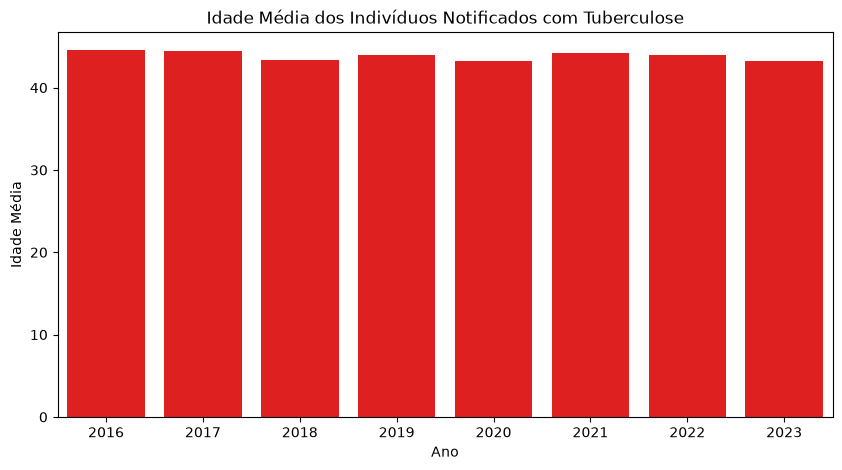

In [18]:
plt.figure(figsize=(10,5))

sns.barplot(data=idade_media_anual, x='NU_ANO', y='IDADE_ANOS' , color='red')
plt.title('Idade Média dos Indivíduos Notificados com Tuberculose')
plt.xlabel('Ano')
plt.ylabel('Idade Média')

Text(0, 0.5, 'Idade Média')

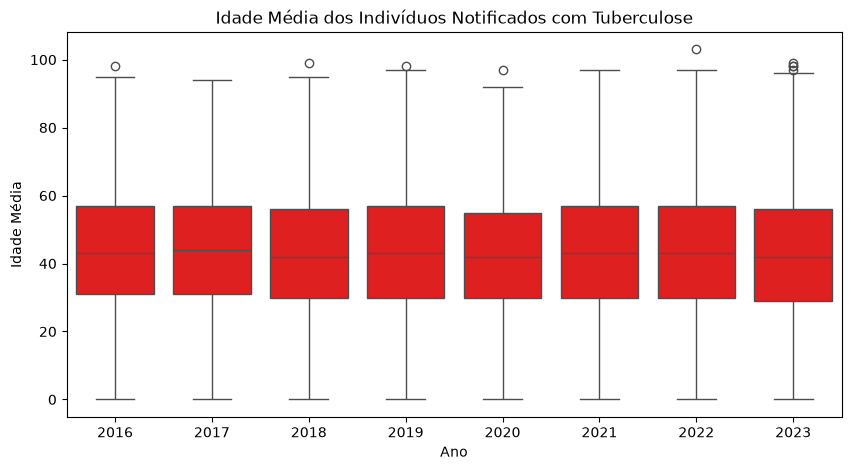

In [19]:
#Boxplot das idades nos anos
plt.figure(figsize=(10,5))

sns.boxplot(data=df_minas, x='NU_ANO', y='IDADE_ANOS' , color='red')
plt.title('Idade Média dos Indivíduos Notificados com Tuberculose')
plt.xlabel('Ano')
plt.ylabel('Idade Média')

Text(0, 0.5, 'Idade Média')

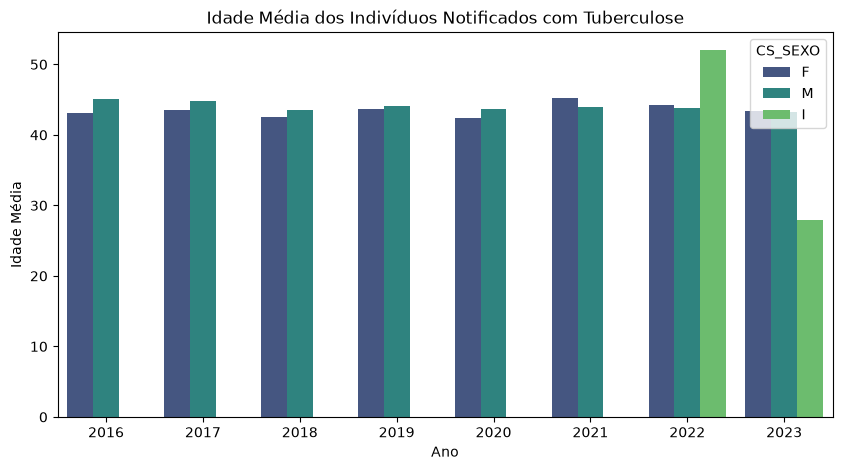

In [20]:
df_group = df_minas.groupby(['NU_ANO', 'CS_SEXO'])['IDADE_ANOS'].mean().reset_index()
plt.figure(figsize=(10,5))

sns.barplot(data=df_group, x='NU_ANO', y='IDADE_ANOS', hue='CS_SEXO', palette='viridis')
plt.title('Idade Média dos Indivíduos Notificados com Tuberculose')
plt.xlabel('Ano')
plt.ylabel('Idade Média')

In [21]:
#Tratando as colunas dummies com strings

var_dummy = {'M':0, 'F':1}

df_minas['CS_SEXO'] = df_minas['CS_SEXO'].map(var_dummy)

Queremos criar uma coluna de desfecho com   
- 0 representa não óbito  
- 1 representa óbito  

In [22]:
df_minas['OBITO'] = np.where(df_minas['SITUA_ENCE'] == 3, 1,0)
df_minas = df_minas.drop(columns=['SITUA_ENCE'])

In [23]:
df_minas[['CS_RACA']].value_counts()

CS_RACA
4.0        16737
1.0        10218
2.0         6419
9.0         1683
3.0          324
5.0           82
0.0           77
Name: count, dtype: int64

In [24]:
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
ohe_cols = ohe.fit_transform(df_minas[['CS_RACA']])
pd.DataFrame(ohe_cols)

,0,1,2,3,4,5,6,7
0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
35648,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
35649,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
35650,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
35651,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
